# MHTSK: many short rules instead of a few long ones

This notebook follows, one step at a time, the classifier of

> Z. Bian, Q. Chang, J. Wang and N. R. Pal, "Multihead Takagi-Sugeno-Kang fuzzy system",
> *IEEE Transactions on Fuzzy Systems*, 2025.

on Colon, one of the datasets of the article. MHTSK builds its rule base from many
"heads": each head draws a small random subset of the features, clusters the data on it
and contributes a few short rules. The notebook is a short version of the script
`examples/reproductions/mhtsk_2025.py`, which runs two datasets with ten splits; here
three splits of one dataset run in about two minutes.

1. settings and reproducibility;
2. the data;
3. one split with the defaults: the heads and their rules;
4. what the fitted model looks like;
5. three splits, next to the article.

## 1. Settings and reproducibility

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import torch
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler

import highfis
from highfis import MHTSKClassifier

In [2]:
SEED = 1
REPETITIONS = 3
THREADS = 4

# Table VI of the article, Colon: mean and standard deviation of the test accuracy.
ARTICLE = (88.95, 5.0)

torch.set_num_threads(THREADS)
torch.use_deterministic_algorithms(True)
highfis.set_mf_cache_enabled(False)

## 2. The data

Colon is a gene-expression dataset: 62 tissue samples, 2000 genes, two classes. OpenML
stores it as a sparse matrix.

In [3]:
bunch = fetch_openml(data_id=1432, as_frame=False, parser="liac-arff")
data = bunch.data.toarray() if hasattr(bunch.data, "toarray") else bunch.data
features = np.asarray(data, dtype=np.float32)
labels = np.unique(bunch.target, return_inverse=True)[1]

print(f"{features.shape[0]} samples, {features.shape[1]} features")
print(f"samples per class: {np.bincount(labels).tolist()}")

62 samples, 2000 features
samples per class: [40, 22]


The article keeps 70% of the samples for training and scales the inputs to [0, 1] with
the range of the training part. The test part has 19 samples.

In [4]:
x_train, x_test, y_train, y_test = train_test_split(features, labels, train_size=0.7, random_state=SEED)

scaler = MinMaxScaler().fit(x_train)
x_train, x_test = scaler.transform(x_train), scaler.transform(x_test)

print(f"training: {len(x_train)} samples, test: {len(x_test)} samples")

training: 43 samples, test: 19 samples


## 3. One split with the defaults

For up to 5000 features the article uses 200 heads, each with 2% of the features; each
head clusters 80% of the training samples with fuzzy C-means and gives three rules, with
spreads fixed at one. The consequents start at zero and are the only trained parameters.
These are the defaults of `MHTSKClassifier` above 1000 features.

In [5]:
model = MHTSKClassifier(random_state=SEED).fit(x_train, y_train)

print(f"rules: {model.model_.n_rules}")
print(f"training accuracy: {100 * model.score(x_train, y_train):.1f}%")
print(f"test accuracy: {100 * model.score(x_test, y_test):.1f}%")

rules: 600
training accuracy: 97.7%
test accuracy: 84.2%


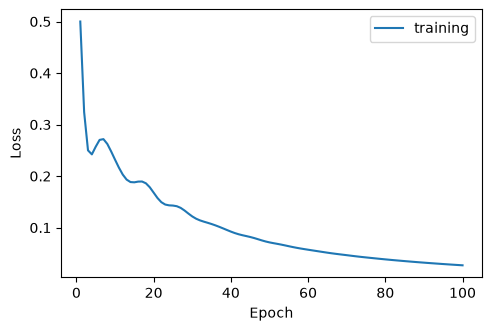

In [6]:
model.plot_history()
plt.show()

## 4. What the fitted model looks like

A rule of an ordinary system on these data would have 2000 conditions. A rule of MHTSK
has the 40 features of its head, so the product of its membership degrees does not
underflow, and all the rules are normalized together. No rule dominates:

In [7]:
report = model.firing_diagnostics(x_train)
print(f"samples with the same weight on every rule: {100 * report['uniform_fraction']:.0f}%")
print(f"samples on which one rule has 99% of the weight: {100 * report['dominated_fraction']:.0f}%")
print(f"effective number of rules per sample: {report['effective_rules']:.0f} of {report['n_rules']}")

samples with the same weight on every rule: 0%
samples on which one rule has 99% of the weight: 0%
effective number of rules per sample: 585 of 600


The mean weight of each of the rules on the training samples, sorted:

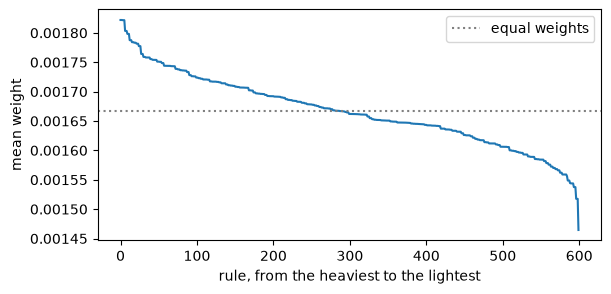

In [8]:
weights = np.sort(report["mean_firing"])[::-1]

fig, ax = plt.subplots(figsize=(6.5, 3))
ax.plot(weights)
ax.axhline(1 / len(weights), color="gray", linestyle=":", label="equal weights")
ax.set_xlabel("rule, from the heaviest to the lightest")
ax.set_ylabel("mean weight")
ax.legend()
plt.show()

The confusion matrix on the 19 test samples, with the margin of each decision:

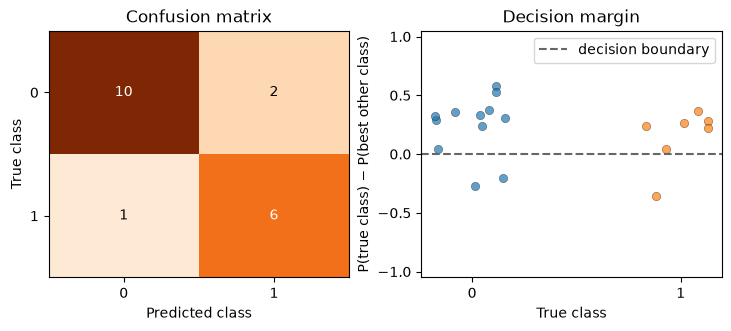

In [9]:
model.plot_diagnostics(x_test, y_test)
plt.show()

Which genes the model relies on: the twenty largest values of the importance computed
from the consequents. The genes are numbered from one, in the order of the columns of the
data.

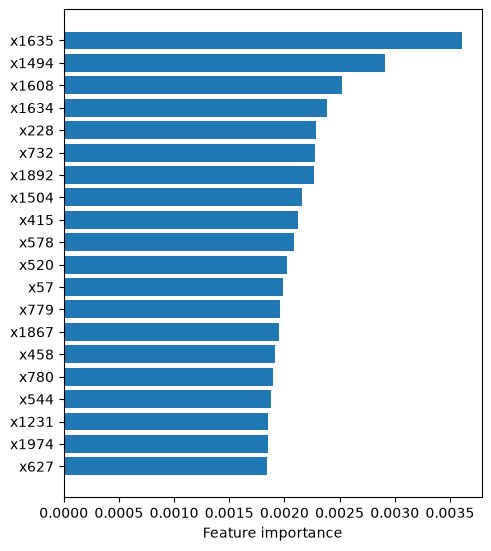

In [10]:
model.plot_feature_importance(top=20)
plt.show()

A summary of the model and of its training, in one call:

In [11]:
print(model.summary())

MHTSKClassifier
  task               classification, 2 classes
  features           2000 seen in fit, 2000 used by the model
  rules              600 (rule base: custom)
  fuzzy sets         1 or 4 or 7 or 10 or 13 or 16 or 19 or 22 or 25 or 28 or 31 or 34 or 37 per feature, ConstantMF, GaussianMF
  firing strength    RuleLayer, T-norm ProductTNorm
  defuzzifier        SumBasedDefuzzifier
  consequents        SparseClassificationConsequentLayer
  parameters         2401200 trainable (0 antecedent, 2401200 consequent)
Training
  batch size         64
  epochs             100 epochs, learning rate 0.01, training loss 0.5000 -> 0.0269, training accuracy 0.9767


How the rules produce the prediction of the first test sample. The output is the sum of
what each rule contributes, and the predicted class is the one with the largest value:

In [12]:
print(model.explain(x_test[0]))

Prediction: 1
Output, the sum of the contributions of the 600 rules: 0: +0.22, 1: +0.80
Rule 440, weight 0.00: contributes 0: +0.00, 1: -0.00
    IF ... (40 more)
Rule 438, weight 0.00: contributes 0: +0.00, 1: -0.00
    IF ... (40 more)
Rule 439, weight 0.00: contributes 0: +0.00, 1: -0.00
    IF ... (40 more)
597 other rules, weight 0.99 in all: contribute 0: +0.21, 1: +0.80


How well the rules cover the samples: for each sample, the mean membership degree in its
best-matching rule. A test sample with a coverage well below the training samples would
lie outside the region the rules were built on:

In [13]:
inside, outside = model.coverage(x_train), model.coverage(x_test)
print(f"training part: min {inside.min():.2f}, median {np.median(inside):.2f}")
print(f"test part:     min {outside.min():.2f}, median {np.median(outside):.2f}")

training part: min 0.98, median 0.99
test part:     min 0.97, median 0.99


## 5. Three splits, next to the article

With 19 test samples the accuracy of one split says little. The article reports the mean
of ten random splits; three are run here, and the script runs the ten.

In [14]:
scores = []
for repetition in range(REPETITIONS):
    seed = SEED + repetition
    a_train, a_test, b_train, b_test = train_test_split(features, labels, train_size=0.7, random_state=seed)
    scaler = MinMaxScaler().fit(a_train)
    fitted = MHTSKClassifier(random_state=seed).fit(scaler.transform(a_train), b_train)
    scores.append(100 * fitted.score(scaler.transform(a_test), b_test))
    print(f"split {seed}: {scores[-1]:.1f}%")

print(f"\nhighFIS: {np.mean(scores):.2f} +- {np.std(scores):.2f}   article: {ARTICLE[0]:.2f} +- {ARTICLE[1]:.0f}")

split 1: 84.2%


split 2: 94.7%


split 3: 89.5%

highFIS: 89.47 +- 4.30   article: 88.95 +- 5


Over the ten splits of the script the mean is 87.90, with a standard deviation of 7.08.

## Environment

In [15]:
highfis.show_versions()

highfis       : 0.33.0
python        : 3.11.15
platform      : Linux-7.0.0-38-generic-x86_64-with-glibc2.43
torch         : 2.14.1+cu130
numpy         : 2.4.6
scikit-learn  : 1.9.1
default dtype : torch.float32
threads       : 4
cpu           : Intel(R) Core(TM) Ultra 7 258V
